In [1]:
import numpy as np
import matplotlib.pyplot as plt
from parflow.tools import Run
from parflow.tools.fs import mkdir, cp, get_absolute_path, exists
import matplotlib.pyplot as plt
from matplotlib import colors 
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
import matplotlib.patches as mpatches
from matplotlib.patches import Patch

from matplotlib.ticker import MultipleLocator

In [8]:
runname = 'baseline.wy2017'
run_dir=''
run_dir = get_absolute_path(runname)

path_run = f'/hydrodata/temp/EastTaylor_ashley/new_runs/{runname}/'
run = Run.from_definition(f'{path_run}{runname}.pfidb')

data = run.data_accessor # creating data accessor object 
dx = data.dx
dy = data.dy
dz = data.dz

nz,ny,nx = data.shape

porosity= data.computed_porosity
specific_storage = data.specific_storage
mask = data.mask
mask[mask>0]=1 # PF has big # instead of 1 so change to 1 bc more manageable
surf_mask = mask[-1,:,:] # last element of first axis (always be surface no matter what)
nanmask=mask.copy()
nanmask[nanmask == 0] = 'NaN'
nanmask[nanmask > 0] = 1

july_start_hr = 273*24
june_start_hr = 243*24
september_end_hr = 365*24

Solver: Field BinaryOutDir is not part of the expected schema <class 'parflow.tools.database.generated.Solver'>
  - nt
  - sw_ini
  - hkdepth
  - wtfact
  - trsmx0
  - smpmax
  - pondmx


In [3]:
swe_2017 = np.load('/home/ad4430/new_runs/pf_out_WY2017_baseline/swe.npy')
swe_2017_warm = np.load('/home/ad4430/new_runs/pf_out_WY2017_warm/swe.npy')

swe_2018 = np.load('/home/ad4430/new_runs/pf_out_WY2018_baseline/swe.npy')
swe_2018_warm = np.load('/home/ad4430/new_runs/pf_out_WY2018_warm/swe.npy')


In [5]:
def snow_disappearance_peak(swe, threshold=10):

    # get rid of first tstep IC 
    swe = swe[1:,:,:]
    print(swe.shape)
    
    # Convert hourly SWE to daily mean
    n_days = swe.shape[0] // 24

    swe_daily = swe[:n_days * 24].reshape(
        n_days, 24, *swe.shape[1:]
    ).mean(axis=1)
    print(swe_daily.shape)
    # day and value of peak SWE
    peak_day = np.nanargmax(swe_daily, axis=0)

    peak_swe = np.nanmax(swe_daily, axis =0)
    
    days = np.arange(n_days)[:, None, None]

    # mask to ony consider times after peak SWE
    after_peak = days > peak_day[None, :, :]

    # SWE below disappearance threshold
    disappeared = (swe_daily < threshold) & after_peak

    # first occurrence after peak
    sdd = np.argmax(disappeared, axis=0).astype(float)

    # np.argmax returns 0 if condition never occurs,
    # so explicitly remove those cells
    never_disappears = ~np.any(disappeared, axis=0)
    print(len(never_disappears))
    sdd[never_disappears] = np.nan

    # no meaningful snowpack if peak SWE never exceeded threshold
    no_meaningful_snow = peak_swe < threshold
    sdd[no_meaningful_snow] = np.nan
    peak_swe[no_meaningful_snow] = np.nan
    
    return sdd, peak_swe

In [12]:
sdd_2017, peak_swe_2017 = snow_disappearance_peak(swe_2017)
sdd_2017_warm, peak_swe_2017_warm = snow_disappearance_peak(swe_2017_warm)
swe_change_2017 = peak_swe_2017_warm - peak_swe_2017
sdd_change_2017 = sdd_2017_warm - sdd_2017

sdd_2018, peak_swe_2018 = snow_disappearance_peak(swe_2018)
sdd_2018_warm, peak_swe_2018_warm = snow_disappearance_peak(swe_2018_warm)
swe_change_2018 = peak_swe_2018_warm - peak_swe_2018
sdd_change_2018 = sdd_2018_warm - sdd_2018

(8760, 48, 67)
(365, 48, 67)
48
(8760, 48, 67)
(365, 48, 67)
48
(8760, 48, 67)
(365, 48, 67)
48
(8760, 48, 67)
(365, 48, 67)
48


In [4]:
## change in pixels recieving snow
snow_mask_2017 = np.any(swe_2017 > 10, axis=0)
print(np.sum(snow_mask_2017))
snow_mask_2017_warm = np.any(swe_2017_warm > 10, axis=0)
print(np.sum(snow_mask_2017_warm))


snow_mask_2018 = np.any(swe_2018 > 10, axis=0)
print(np.sum(snow_mask_2018))
snow_mask_2018_warm = np.any(swe_2018_warm > 10, axis=0)
print(np.sum(snow_mask_2018_warm))

1883
1883
1883
1871


In [9]:
# change in avg 10 cm soil saturation in mm due to warming

# subsurface storage from parflow 
subsurf_stor_2017 = np.load('/home/ad4430/new_runs/pf_out_WY2017_baseline/sub_storage.npy')
subsurf_stor_2017_warm = np.load('/home/ad4430/new_runs/pf_out_WY2017_warm/sub_storage.npy')
subsurf_stor_2017_warm.shape

subsurf_stor_2018= np.load('/home/ad4430/new_runs/pf_out_WY2018_baseline/sub_storage.npy')
subsurf_stor_2018_warm = np.load('/home/ad4430/new_runs/pf_out_WY2018_warm/sub_storage.npy')
print(subsurf_stor_2017.shape)

subsurf_stor_2017 = subsurf_stor_2017[july_start_hr : september_end_hr, :, :] * surf_mask
subsurf_stor_2017_warm = subsurf_stor_2017_warm[july_start_hr : september_end_hr, :, :] * surf_mask

subsurf_stor_2018 = subsurf_stor_2018[july_start_hr : september_end_hr, :, :] * surf_mask
subsurf_stor_2018_warm = subsurf_stor_2018_warm[july_start_hr : september_end_hr, :, :] * surf_mask

# change in starting subsurface storage over the summer
avg_sub_2017 = subsurf_stor_2017[0, -2:, :, :].sum(axis=0)
avg_sub_2017_warm = subsurf_stor_2017_warm[0, -2:, :, :].sum(axis=0)

avg_sub_2018 = subsurf_stor_2018[0, -2:, :, :].sum(axis=0)
avg_sub_2018_warm = subsurf_stor_2018_warm[0, -2:, :, :].sum(axis=0)

# avg_sub_2018 = subsurf_stor_2018.nanmean(axis = 0)[-2:].sum(axis=0)
# avg_sub_2018_warm = subsurf_stor_2018_warm.nanmean(axis = 0)[-2:].sum(axis=0)

avg_sub_2017.shape

(8761, 10, 48, 67)


(48, 67)

In [10]:
# divide by pixel size (1km2 = 1e12 mm2)
# currently in m3 = 1e9 mm3
sub_change_2018 = (avg_sub_2018_warm - avg_sub_2018) * 10**9 / 10**12 # m3 to mm


sub_change_2017 = (avg_sub_2017_warm - avg_sub_2017) * 10**9 / 10**12 # m3 to mm

/tmp/ipykernel_301821/1771845424.py:92: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


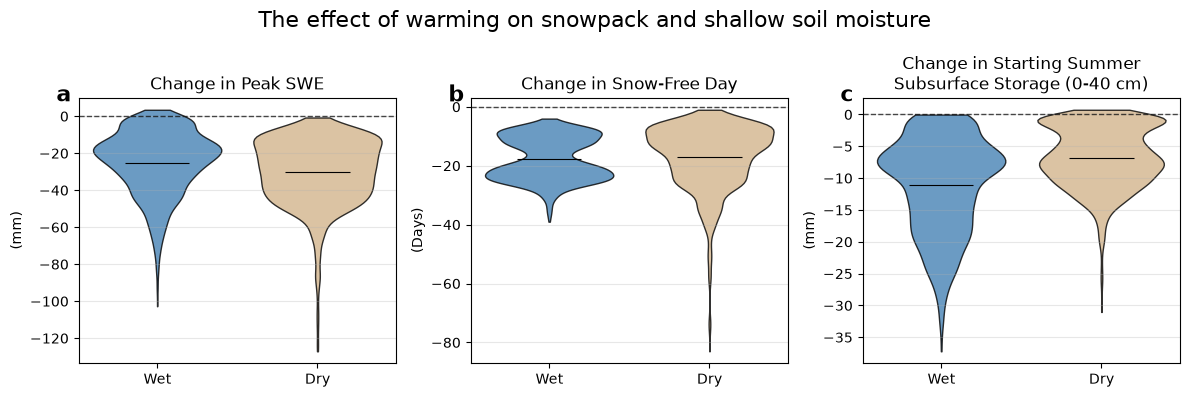

In [13]:
# violin plots
# Flatten arrays and remove NaN/inf values
def clean_array(array):
    array = np.asarray(array).ravel()
    return array[np.isfinite(array)]

swe_change_2017_masked = np.where(surf_mask == 1, swe_change_2017, np.nan)
swe_change_2018_masked = np.where(surf_mask == 1, swe_change_2018, np.nan)

days_early_2017_masked = np.where(
    surf_mask == 1, sdd_change_2017, np.nan
)

days_early_2018_masked = np.where(
    surf_mask == 1, sdd_change_2018, np.nan
)


sub_change_2017_masked = np.where(surf_mask == 1, sub_change_2017, np.nan)
sub_change_2018_masked = np.where(surf_mask == 1, sub_change_2018, np.nan)

plot_data = [
    {
        "values": [clean_array(swe_change_2017_masked), clean_array(swe_change_2018_masked)],
        "title": "Change in Peak SWE",
        "ylabel": "(mm)",
    },
    {
        "values": [clean_array(days_early_2017_masked), clean_array(days_early_2018_masked)],
        "title": "Change in Snow-Free Day",
        "ylabel": "(Days)",
    },
    {
        "values": [clean_array(sub_change_2017_masked), clean_array(sub_change_2018_masked)],
        "title": 'Change in Starting Summer\nSubsurface Storage (0-40 cm)',
        "ylabel": "(mm)",
    },
]

colors = ["steelblue", "tan"]
labels = ["Wet", "Dry"]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 4),
    constrained_layout=True
)

letters = ["a", "b", "c"]

for ax, info, letter in zip(axes, plot_data, letters):

    violin = ax.violinplot(
        info["values"],
        positions=[1, 2],
        widths=0.8,
        showmeans=True,
        showmedians=False,
        showextrema=False,
    )
    
    # Set violin colors
    for body, color in zip(violin["bodies"], colors):
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_alpha(0.8)

    # Format median and extrema lines
    for line_name in ["cmeans"]:#, "cmins", "cmaxes", "cbars"]:
        violin[line_name].set_color("black")
        violin[line_name].set_linewidth(0.8)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(labels)
    ax.set_title(info["title"])
    ax.set_ylabel(info["ylabel"])
    ax.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
    ax.grid(axis="y", alpha=0.3)

    # Panel label
    ax.text(
        -0.07, 1.05, letter,
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="top",
        ha="left"
    )
fig.suptitle("The effect of warming on snowpack and shallow soil moisture", fontsize=16)

plt.tight_layout()
plt.show()